In [2]:
import pandas as pd
df=pd.read_csv("/content/sentiment_10000_tweets_emojis_raw.csv")

In [3]:
df.head()

,tweet_id,text,sentiment,sentiment_label
0,TW008016,"@alex After trying it, THE course material wo...",1,positive
1,TW000923,Just noticed the delivery fell short of my exp...,0,negative
2,TW002002,"This week, the restaurant impressed me a lot. ...",1,positive
3,TW007626,Just noticed the customer support was quick an...,1,positive
4,TW001517,I think the internet connection was terrible. ...,0,negative


Dataset Shape: (10000, 4)
   tweet_id                                               text  sentiment  \
0  TW008016  @alex  After trying it, THE course material wo...          1   
1  TW000923  Just noticed the delivery fell short of my exp...          0   
2  TW002002  This week, the restaurant impressed me a lot. ...          1   
3  TW007626  Just noticed the customer support was quick an...          1   
4  TW001517  I think the internet connection was terrible. ...          0   

  sentiment_label  
0        positive  
1        negative  
2        positive  
3        positive  
4        negative  
['tweet_id', 'text', 'sentiment', 'sentiment_label']

Cleaned Dataset:
                                                text  \
0  @alex  After trying it, THE course material wo...   
1  Just noticed the delivery fell short of my exp...   
2  This week, the restaurant impressed me a lot. ...   
3  Just noticed the customer support was quick an...   
4  I think the internet connection was t

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 7)              │         5,971 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_4 (Dense)          │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_5 (Dense)          │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,203 (24.23 KB)

 Trainable params: 6,203 (24.23 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
171/193 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6144 - loss: 0.6357
Epoch 1: val_loss improved from None to 0.06994, saving model to best_sentiment_ann.keras

Epoch 1: finished saving model to best_sentiment_ann.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8094 - loss: 0.4548 - val_accuracy: 1.0000 - val_loss: 0.0699
Epoch 2/30
177/193 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0294
Epoch 2: val_loss improved from 0.06994 to 0.00217, saving model to best_sentiment_ann.keras

Epoch 2: finished saving model to best_sentiment_ann.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 1.0000 - loss: 0.0134 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 3/30
186/193 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0016
Epoch 3: val_loss improved from 0.00217 to 0.00070, saving model to best_sentiment_ann.keras

Epoch 3: finished saving model to best_sentiment_ann.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy:

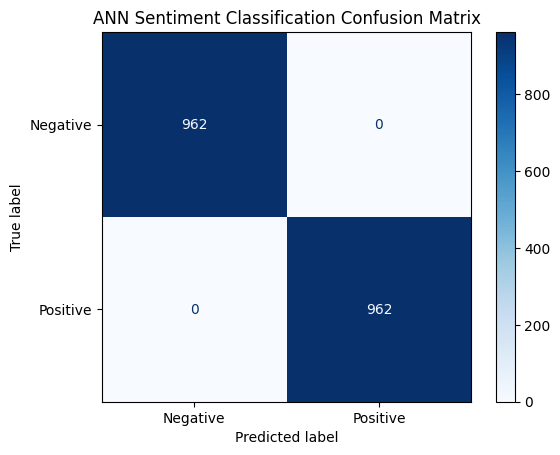

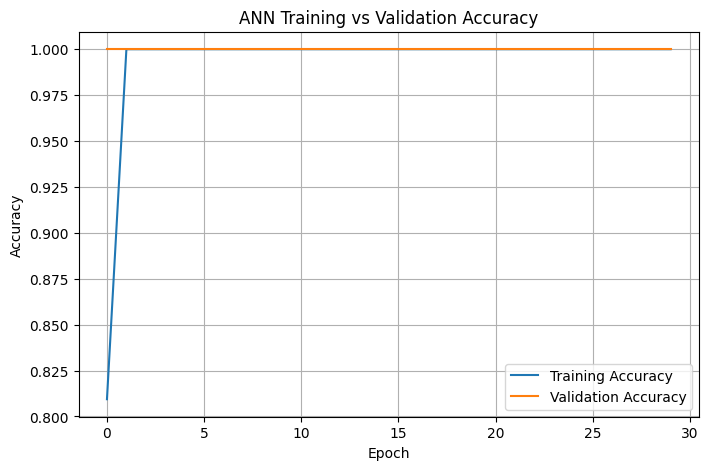

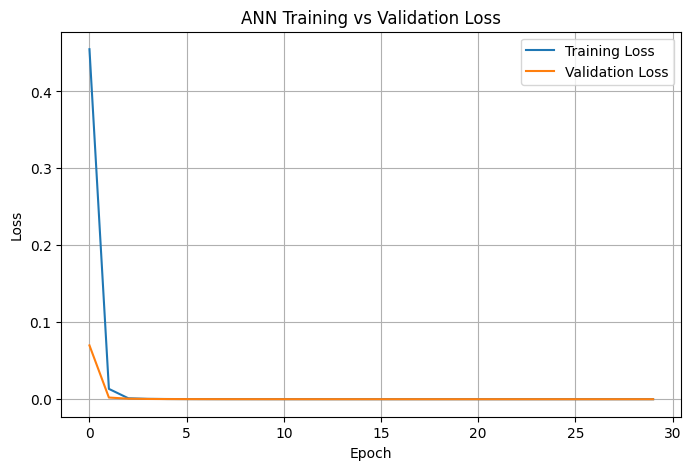


Original Tweet: I absolutely love this product! Amazing experience 😍
Cleaned Tweet: i absolutely love this product amazing experience
Predicted Sentiment: Negative
Confidence: 52.72 %

Original Tweet: This is the worst service I have ever experienced 😡
Cleaned Tweet: this is the worst service i have ever experienced
Predicted Sentiment: Negative
Confidence: 58.35 %

Original Tweet: Excellent quality and very fast delivery!
Cleaned Tweet: excellent quality and very fast delivery
Predicted Sentiment: Positive
Confidence: 99.99 %

Original Tweet: I am disappointed with the customer support
Cleaned Tweet: i am disappointed with the customer support
Predicted Sentiment: Positive
Confidence: 57.35 %

Model, Vectorizer and Predictions Saved!


In [5]:

# ============================================================
# SENTIMENT ANALYSIS USING ANN
# 5 HIDDEN LAYERS - 7 NEURONS IN EACH LAYER
# ============================================================

# STEP 1: IMPORT LIBRARIES

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)


# ============================================================
# STEP 2: LOAD DATASET
# ============================================================

# Upload your CSV to Colab before running
df = pd.read_csv("/content/sentiment_10000_tweets_emojis_raw.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.columns.tolist())


# ============================================================
# STEP 3: DATA PREPROCESSING
# ============================================================

# Remove missing values
df = df.dropna(subset=["text", "sentiment"]).copy()

# Convert sentiment to numeric
df["sentiment"] = df["sentiment"].astype(int)

# Clean text
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove mentions
    text = re.sub(r"@\w+", " ", text)

    # Keep hashtag words
    text = re.sub(r"#(\w+)", r"\1", text)

    # Remove punctuation, emojis and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["cleaned_text"] = df["text"].apply(clean_text)

# Remove empty cleaned tweets
df = df[df["cleaned_text"] != ""].copy()

# Remove exact duplicates
df = df.drop_duplicates(subset=["cleaned_text"])

print("\nCleaned Dataset:")
print(df[["text", "cleaned_text", "sentiment"]].head())


# ============================================================
# STEP 4: DEFINE INPUT AND OUTPUT
# ============================================================

X = df["cleaned_text"]
y = df["sentiment"]

# Positive = 1
# Negative = 0

print("\nSentiment Distribution:")
print(y.value_counts())


# ============================================================
# STEP 5: TRAIN TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


# ============================================================
# STEP 6: TEXT TO NUMERICAL FEATURES USING TF-IDF
# ============================================================

vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

# Fit only on training data to avoid leakage
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Convert sparse matrices to dense arrays for ANN
X_train_array = X_train_tfidf.toarray().astype("float32")
X_test_array = X_test_tfidf.toarray().astype("float32")

print("Training Input Shape:", X_train_array.shape)
print("Testing Input Shape:", X_test_array.shape)


# ============================================================
# STEP 7: BUILD ANN MODEL
# 5 HIDDEN LAYERS - 7 NEURONS EACH
# ============================================================

model = Sequential([

    # Input Layer
    Input(shape=(X_train_array.shape[1],)),

    # Hidden Layer 1
    Dense(
        7,
        activation="relu",
        name="Hidden_Layer_1"
    ),

    # Hidden Layer 2
    Dense(
        7,
        activation="relu",
        name="Hidden_Layer_2"
    ),

    # Hidden Layer 3
    Dense(
        7,
        activation="relu",
        name="Hidden_Layer_3"
    ),

    # Hidden Layer 4
    Dense(
        7,
        activation="relu",
        name="Hidden_Layer_4"
    ),

    # Hidden Layer 5
    Dense(
        7,
        activation="relu",
        name="Hidden_Layer_5"
    ),

    # Output Layer
    Dense(
        1,
        activation="sigmoid",
        name="Output_Layer"
    )

])


# ============================================================
# STEP 8: COMPILE ANN MODEL
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ============================================================
# STEP 9: MODEL CHECKPOINT
# ============================================================

checkpoint = ModelCheckpoint(
    filepath="best_sentiment_ann.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)


# ============================================================
# STEP 10: TRAIN ANN MODEL
# ============================================================

history = model.fit(
    X_train_array,
    y_train.to_numpy(),
    validation_split=0.20,
    epochs=30,
    batch_size=32,
    callbacks=[checkpoint, early_stopping],
    verbose=1
)


# ============================================================
# STEP 11: EVALUATE ANN MODEL
# ============================================================

test_loss, test_accuracy = model.evaluate(
    X_test_array,
    y_test.to_numpy(),
    verbose=0
)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


# ============================================================
# STEP 12: PREDICT TEST DATA
# ============================================================

# Predict probability of positive sentiment
y_probability = model.predict(
    X_test_array,
    verbose=0
).flatten()

# Convert probability into binary class
y_pred = (y_probability >= 0.5).astype(int)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)


# ============================================================
# STEP 13: SHOW ACTUAL VS PREDICTED OUTPUT
# ============================================================

results = pd.DataFrame({

    "tweet": X_test.values,

    "actual_sentiment": y_test.values,

    "predicted_sentiment": y_pred,

    "positive_probability": y_probability

})

results["actual_label"] = results[
    "actual_sentiment"
].map({0: "Negative", 1: "Positive"})

results["predicted_label"] = results[
    "predicted_sentiment"
].map({0: "Negative", 1: "Positive"})

print("\nPrediction Results:")
print(results.head(20).to_string(index=False))


# ============================================================
# STEP 14: CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(cmap="Blues")

plt.title("ANN Sentiment Classification Confusion Matrix")
plt.show()


# ============================================================
# STEP 15: TRAINING ACCURACY VS VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# STEP 16: TRAINING LOSS VS VALIDATION LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# STEP 17: PREDICT NEW TWEETS
# ============================================================

def predict_sentiment(tweet):

    # Apply same preprocessing
    cleaned = clean_text(tweet)

    # Convert text into TF-IDF
    features = vectorizer.transform(
        [cleaned]
    ).toarray().astype("float32")

    # Predict positive probability
    probability = float(
        model.predict(features, verbose=0)[0][0]
    )

    # Binary classification
    sentiment = (
        "Positive" if probability >= 0.5
        else "Negative"
    )

    confidence = (
        probability if probability >= 0.5
        else 1 - probability
    )

    print("\nOriginal Tweet:", tweet)
    print("Cleaned Tweet:", cleaned)
    print("Predicted Sentiment:", sentiment)
    print("Confidence:", round(confidence * 100, 2), "%")

    return sentiment


# ============================================================
# STEP 18: TEST WITH NEW TWEETS
# ============================================================

predict_sentiment(
    "I absolutely love this product! Amazing experience 😍"
)

predict_sentiment(
    "This is the worst service I have ever experienced 😡"
)

predict_sentiment(
    "Excellent quality and very fast delivery!"
)

predict_sentiment(
    "I am disappointed with the customer support"
)


# ============================================================
# STEP 19: SAVE MODEL AND VECTORIZER
# ============================================================

model.save("sentiment_ann_final.keras")

joblib.dump(
    vectorizer,
    "sentiment_tfidf_vectorizer.pkl"
)

results.to_csv(
    "ann_sentiment_predictions.csv",
    index=False
)

print("\nModel, Vectorizer and Predictions Saved!")
